In [1]:
%pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv("heart.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
print("Column information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target  

In [5]:
X = df.drop("target", axis=1)
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1025, 13)
Target shape: (1025,)


In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (615, 13)
Validation set: (205, 13)
Testing set: (205, 13)


In [7]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_val_scaled = preprocessor.transform(X_val)
X_test_scaled = preprocessor.transform(X_test)

print("Training data after preprocessing:")
print(X_train_scaled[:5])

Training data after preprocessing:
[[ 1.34998779  0.66607955 -0.90774159 -1.81826467  0.94890935 -0.42476142
  -1.00408294 -1.10023728  1.42462509 -0.14628581 -0.59360873  1.20054247
  -0.5784663 ]
 [-0.08165465  0.66607955  1.01398329 -0.68449931  0.17410448 -0.42476142
  -1.00408294 -0.12036561 -0.70193906 -0.55935181 -0.59360873 -0.73988754
   1.11561359]
 [-1.73354978 -1.50132217  1.01398329 -2.15839427 -0.94085864 -0.42476142
   0.90181523  1.30490228 -0.70193906 -0.8898046   0.98677816 -0.73988754
  -0.5784663 ]
 [ 0.13859803 -1.50132217 -0.90774159  0.10913644  3.02765414 -0.42476142
  -1.00408294  0.01325325  1.42462509  0.67984618 -0.59360873  1.20054247
   1.11561359]
 [ 1.46011413  0.66607955 -0.90774159  0.67601912 -1.05424472  2.35426277
   0.90181523 -0.38760334 -0.70193906  1.91904417 -0.59360873  1.20054247
   1.11561359]]


In [8]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

y_val_log = log_model.predict(X_val_scaled)

print("Logistic Regression Results")
print("Accuracy:", round(accuracy_score(y_val, y_val_log), 4))
print("Precision:", round(precision_score(y_val, y_val_log, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_log, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_val_log, zero_division=0), 4))

Logistic Regression Results
Accuracy: 0.8195
Precision: 0.7931
Recall: 0.8762
F1-score: 0.8326


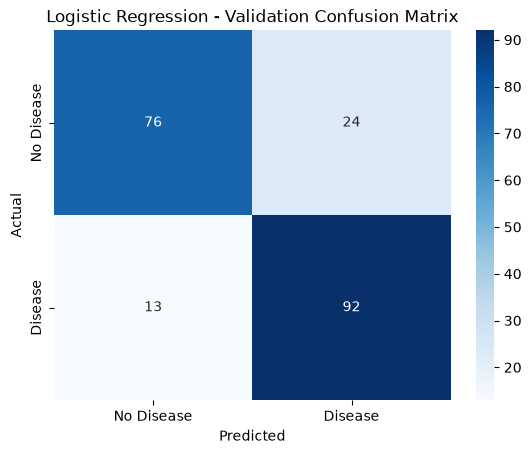

In [9]:
cm = confusion_matrix(y_val, y_val_log)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()

In [10]:
linear_svm = SVC(kernel="linear", C=1.0)

linear_svm.fit(X_train_scaled, y_train)

y_val_linear = linear_svm.predict(X_val_scaled)

print("Linear SVM")
print("Accuracy:", round(accuracy_score(y_val, y_val_linear), 4))
print("F1-score:", round(f1_score(y_val, y_val_linear, zero_division=0), 4))

Linear SVM
Accuracy: 0.8146
F1-score: 0.8288


In [11]:
rbf_svm = SVC(kernel="rbf", C=1.0, gamma="scale")

rbf_svm.fit(X_train_scaled, y_train)

y_val_rbf = rbf_svm.predict(X_val_scaled)

print("RBF SVM")
print("Accuracy:", round(accuracy_score(y_val, y_val_rbf), 4))
print("F1-score:", round(f1_score(y_val, y_val_rbf, zero_division=0), 4))

RBF SVM
Accuracy: 0.9268
F1-score: 0.9315


In [12]:
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": [0.001, 0.01, 0.1, 1]
    }
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svm', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'svm__C': [0.1, 1, ...], 'svm__kernel': ['linear']}, {'svm__C': [0.1, 1, ...], 'svm__gamma': [0.001, 0.01, ...], 'svm__kernel': ['rbf']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 

In [13]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(grid_search.best_score_, 4))

print("\nBest Model:")
print(grid_search.best_estimator_)

Best Parameters:
{'svm__C': 10, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'}

Best Cross-Validation F1-score:
0.9619

Best Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('svm', SVC(C=10, gamma=0.1))])


In [14]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(grid_search.best_score_, 4))

print("\nBest Model:")
print(grid_search.best_estimator_)

Best Parameters:
{'svm__C': 10, 'svm__gamma': 0.1, 'svm__kernel': 'rbf'}

Best Cross-Validation F1-score:
0.9619

Best Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('svm', SVC(C=10, gamma=0.1))])


In [15]:
results = pd.DataFrame(grid_search.cv_results_)

results = results[
    ["param_svm__kernel", "param_svm__C",
     "param_svm__gamma", "mean_test_score", "rank_test_score"]
].sort_values("rank_test_score")

display(results)

,param_svm__kernel,param_svm__C,param_svm__gamma,mean_test_score,rank_test_score
14,rbf,10.0,0.100,0.961949,1
18,rbf,100.0,0.100,0.960244,2
19,rbf,100.0,1.000,0.953598,3
15,rbf,10.0,1.000,0.953598,3
11,rbf,1.0,1.000,0.947928,5
10,rbf,1.0,0.100,0.910555,6
17,rbf,100.0,0.010,0.898363,7
13,rbf,10.0,0.010,0.882886,8
6,rbf,0.1,0.100,0.869689,9
9,rbf,1.0,0.010,0.860682,10


In [16]:
best_svm = grid_search.best_estimator_

y_val_svm = best_svm.predict(X_val)

print("Tuned SVM - Validation Results")
print("Accuracy:", round(accuracy_score(y_val, y_val_svm), 4))
print("Precision:", round(precision_score(y_val, y_val_svm, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_svm, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_val_svm, zero_division=0), 4))

Tuned SVM - Validation Results
Accuracy: 0.9415
Precision: 0.9266
Recall: 0.9619
F1-score: 0.9439


In [17]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM (C=1)",
        "RBF SVM (C=1)",
        "Tuned SVM"
    ],
    "Validation F1-score": [
        f1_score(y_val, y_val_log, zero_division=0),
        f1_score(y_val, y_val_linear, zero_division=0),
        f1_score(y_val, y_val_rbf, zero_division=0),
        f1_score(y_val, y_val_svm, zero_division=0)
    ]
})

display(comparison.sort_values("Validation F1-score", ascending=False))

,Model,Validation F1-score
3,Tuned SVM,0.943925
2,RBF SVM (C=1),0.931507
0,Logistic Regression,0.832579
1,Linear SVM (C=1),0.828829


In [18]:
y_test_svm = best_svm.predict(X_test)

print("Final Test Results - Tuned SVM")
print("Accuracy:", round(accuracy_score(y_test, y_test_svm), 4))
print("Precision:", round(precision_score(y_test, y_test_svm, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_svm, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_test_svm, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_svm,
    target_names=["No Disease", "Disease"],
    zero_division=0
))

Final Test Results - Tuned SVM
Accuracy: 0.9512
Precision: 0.9524
Recall: 0.9524
F1-score: 0.9524

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.95      0.95      0.95       100
     Disease       0.95      0.95      0.95       105

    accuracy                           0.95       205
   macro avg       0.95      0.95      0.95       205
weighted avg       0.95      0.95      0.95       205



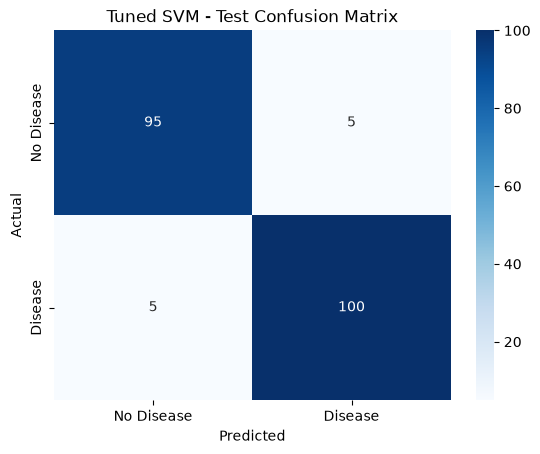

In [19]:
cm = confusion_matrix(y_test, y_test_svm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned SVM - Test Confusion Matrix")
plt.show()

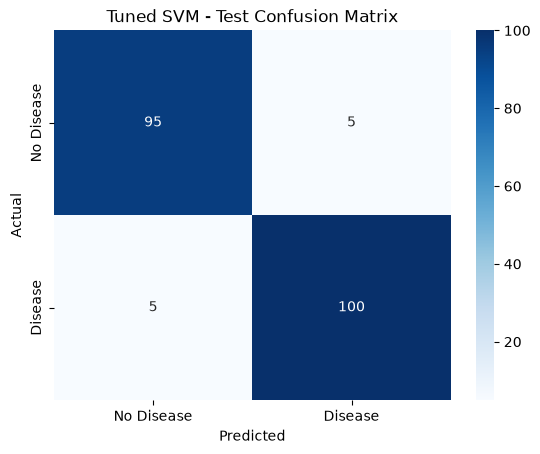

In [20]:
cm = confusion_matrix(y_test, y_test_svm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned SVM - Test Confusion Matrix")
plt.show()

True Negative: 95
False Positive: 5
False Negative: 5
True Positive: 100


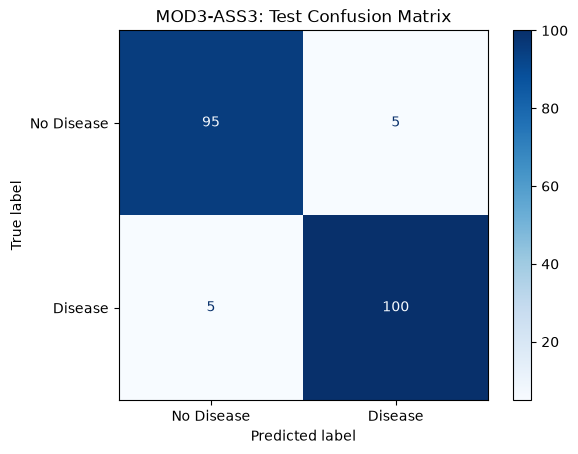

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_test_pred = best_svm.predict(X_test)

cm = confusion_matrix(y_test, y_test_pred)

tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
).plot(cmap="Blues")

plt.title("MOD3-ASS3: Test Confusion Matrix")
plt.show()

In [22]:
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))
print("Sensitivity (%):", round(sensitivity * 100, 2))
print("Specificity (%):", round(specificity * 100, 2))

Sensitivity: 0.9524
Specificity: 0.95
Sensitivity (%): 95.24
Specificity (%): 95.0


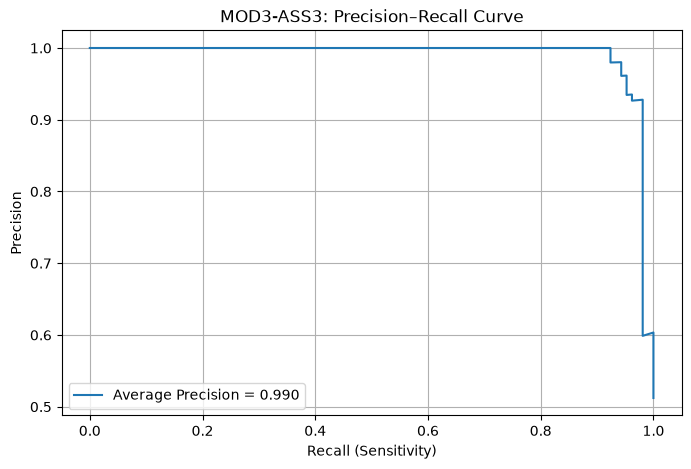

Average Precision: 0.9897


In [23]:
from sklearn.metrics import precision_recall_curve, average_precision_score

y_test_scores = best_svm.decision_function(X_test)

precision, recall, thresholds = precision_recall_curve(
    y_test, y_test_scores
)

ap_score = average_precision_score(y_test, y_test_scores)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"Average Precision = {ap_score:.3f}")
plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("MOD3-ASS3: Precision–Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

print("Average Precision:", round(ap_score, 4))

In [24]:
# Get decision scores on the validation set
y_val_scores = best_svm.decision_function(X_val)

# Calculate precision and recall at candidate thresholds
val_precision, val_recall, val_thresholds = precision_recall_curve(
    y_val, y_val_scores
)

# Use the thresholds corresponding to precision_recall_curve
target_recall = 0.95

# Each threshold has a corresponding precision/recall pair
eligible = np.where(val_recall[:-1] >= target_recall)[0]

if len(eligible) > 0:
    # Select the highest threshold that meets the recall target
    selected_index = eligible[-1]
    chosen_threshold = val_thresholds[selected_index]
    print("Threshold meeting target recall:", chosen_threshold)
    print("Validation recall:", round(val_recall[selected_index], 4))
    print("Validation precision:", round(val_precision[selected_index], 4))
else:
    # If no threshold meets the target, choose the one with highest recall
    selected_index = np.argmax(val_recall)
    chosen_threshold = val_thresholds[0] if len(val_thresholds) else 0.0
    print("Target recall was not achievable with the candidate thresholds.")
    print("Review the validation results before choosing a threshold.")

Threshold meeting target recall: 0.12781886655277308
Validation recall: 0.9619
Validation precision: 0.9439


In [25]:
if len(eligible) > 0:
    selected_index = eligible[-1]
    chosen_threshold = val_thresholds[selected_index]
else:
    # Use a low threshold to favor sensitivity
    chosen_threshold = np.min(y_val_scores) - 1e-6

print("Chosen threshold:", chosen_threshold)

y_val_adjusted = (y_val_scores >= chosen_threshold).astype(int)

print("Adjusted validation sensitivity:",
      round(recall_score(y_val, y_val_adjusted), 4))
print("Adjusted validation precision:",
      round(precision_score(y_val, y_val_adjusted, zero_division=0), 4))
print("Adjusted validation specificity:",
      round(
          confusion_matrix(y_val, y_val_adjusted).ravel()[0] /
          max(confusion_matrix(y_val, y_val_adjusted).ravel()[0] +
              confusion_matrix(y_val, y_val_adjusted).ravel()[1], 1),
          4
      ))

Chosen threshold: 0.12781886655277308
Adjusted validation sensitivity: 0.9619
Adjusted validation precision: 0.9439
Adjusted validation specificity: 0.94


Threshold: 0.1278
Sensitivity: 0.9524
Specificity: 0.96
Precision: 0.9615
F1-score: 0.9569


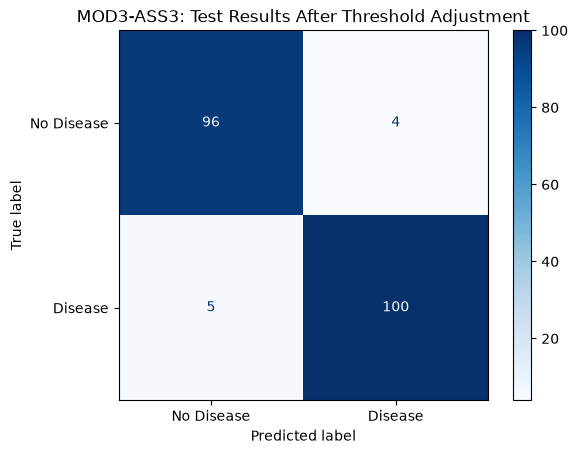

In [26]:
y_test_adjusted_scores = best_svm.decision_function(X_test)

y_test_adjusted = (
    y_test_adjusted_scores >= chosen_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_adjusted, labels=[0, 1]
).ravel()

print("Threshold:", round(float(chosen_threshold), 4))
print("Sensitivity:", round(tp / (tp + fn), 4) if tp + fn else 0)
print("Specificity:", round(tn / (tn + fp), 4) if tn + fp else 0)
print("Precision:", round(precision_score(
    y_test, y_test_adjusted, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_test, y_test_adjusted, zero_division=0
), 4))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test, y_test_adjusted, labels=[0, 1]
    ),
    display_labels=["No Disease", "Disease"]
).plot(cmap="Blues")

plt.title("MOD3-ASS3: Test Results After Threshold Adjustment")
plt.show()

In [27]:
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])

linear_model.fit(X_train, y_train)

print("Linear SVM trained successfully.")
print("Number of features:", len(X_train.columns))

Linear SVM trained successfully.
Number of features: 13


In [28]:
feature_names = X_train.columns

coefficients = linear_model.named_steps["svm"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

top_5 = feature_importance.sort_values(
    by="Importance", ascending=False
).head(5)

display(top_5)

,Feature,Coefficient,Importance
2,cp,0.704425,0.704425
1,sex,-0.536651,0.536651
9,oldpeak,-0.533956,0.533956
11,ca,-0.461800,0.461800
12,thal,-0.419724,0.419724


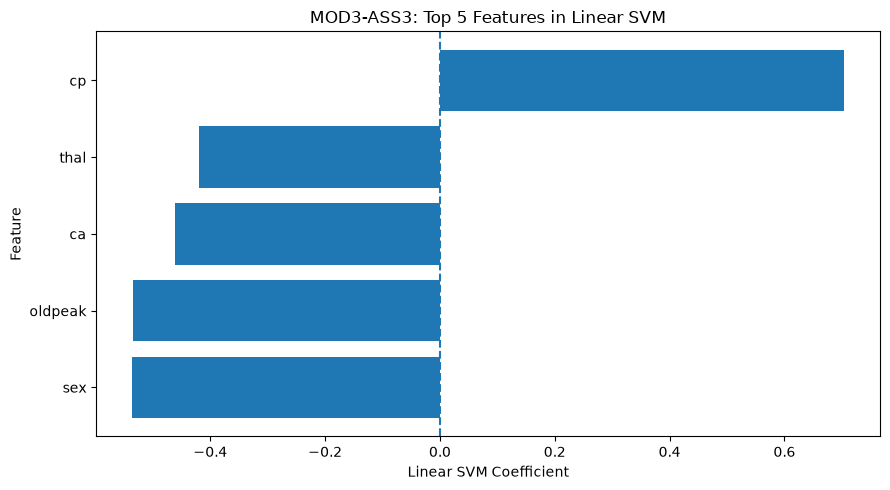

In [29]:
top_5_plot = top_5.sort_values("Coefficient")

plt.figure(figsize=(9, 5))
plt.barh(
    top_5_plot["Feature"],
    top_5_plot["Coefficient"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Linear SVM Coefficient")
plt.ylabel("Feature")
plt.title("MOD3-ASS3: Top 5 Features in Linear SVM")
plt.tight_layout()
plt.show()

In [30]:
medical_context = {
    "age": "Age is an established cardiovascular risk factor.",
    "cp": "Chest pain category can provide clinically relevant information.",
    "thalach": "Maximum heart rate achieved may provide useful clinical information.",
    "oldpeak": "ST depression during exercise can be clinically relevant.",
    "exang": "Exercise-induced angina can be clinically relevant.",
    "ca": "Number of major vessels may provide diagnostic information.",
    "thal": "The thalassemia-related test category may carry diagnostic information.",
    "chol": "Cholesterol is relevant to cardiovascular risk, although its predictive effect varies.",
    "trestbps": "Resting blood pressure is relevant to cardiovascular risk.",
    "sex": "Sex can be associated with differences in cardiovascular risk patterns."
}

print("Top 5 features and medical context:\n")

for _, row in top_5.iterrows():
    feature = row["Feature"]
    print(f"{feature}: coefficient = {row['Coefficient']:.4f}")
    print(medical_context.get(
        feature,
        "Review this feature's definition and clinical meaning in the dataset."
    ))
    print()

Top 5 features and medical context:

cp: coefficient = 0.7044
Chest pain category can provide clinically relevant information.

sex: coefficient = -0.5367
Sex can be associated with differences in cardiovascular risk patterns.

oldpeak: coefficient = -0.5340
ST depression during exercise can be clinically relevant.

ca: coefficient = -0.4618
Number of major vessels may provide diagnostic information.

thal: coefficient = -0.4197
The thalassemia-related test category may carry diagnostic information.



In [32]:

print("\nTop 5 features identified by Linear SVM:")

for _, row in top_5.iterrows():
    direction = (
        "toward disease"
        if row["Coefficient"] > 0
        else "toward no disease"
    )

    print(
        f"{row['Feature']}: "
        f"coefficient = {row['Coefficient']:.4f}, "
        f"direction = {direction}"
    )

print("\nInterpretation:")
print(
    "The Linear SVM identifies features that contribute to its "
    "classification decision. Some findings may align with established "
    "medical knowledge, but coefficients do not prove causation or "
    "measure clinical risk independently."
)


Top 5 features identified by Linear SVM:
cp: coefficient = 0.7044, direction = toward disease
sex: coefficient = -0.5367, direction = toward no disease
oldpeak: coefficient = -0.5340, direction = toward no disease
ca: coefficient = -0.4618, direction = toward no disease
thal: coefficient = -0.4197, direction = toward no disease

Interpretation:
The Linear SVM identifies features that contribute to its classification decision. Some findings may align with established medical knowledge, but coefficients do not prove causation or measure clinical risk independently.
